# PRACTICAL WORK: RANDOM FOREST AND OTHER DECISION TREES-BASED ENSEMBLE LEARNING METHODS

In this practical work, we will explore the application of classification trees and random forests in analyzing a dataset about mice's sleep obtained from CHUV. This dataset includes the Electroencephalogram (EEG) of a mouse, as well as its state. The state of the mouse can be either awake, in REM sleep, or in non-REM sleep (REM and non-REM are two distinct stages of sleep that make up the sleep cycle). The goal will be to predict the state of the mouse based on its EEG. 


EEG is a scientific tool that helps us study brain activity. It records the electrical signals in the brain over time, creating a time serie with detailed patterns. These patterns include things like alpha oscillations suggesting a relaxed but awake state, beta oscillations that might indicate active thinking and focus, or theta oscillations typically observed during deep sleep and non-REM sleep stages.

The problem is that the information about these patterns is spread out over many data points, making it hard to detect directly the main frequency of such oscillations. So, we use something called spectral analysis, which transforms these time series into a different view called the frequency domain. This helps us see the main patterns more clearly by concentrating information about one frequency of oscillation. The process of converting data from the time-domain to the frequency-domain is done thanks to Fourier transforms.

### IMPORTS AND FUNCTIONS

In [2]:
#IMPORTS PACKAGES
import os
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from scipy.stats import randint

## DATA EXPLORATION

Let's look a bit closer at our data. A row was generated each 4 seconds (=15 by minute) during one entire day, giving a dataset of 15x60x24=21600 datapoints. After removing outliers, we are left with 20258 datapoints. For each of this datapoint, the mouse is either awake (w), in REM sleep (r), or in non-REM sleep (n).

In addition to its current state, each datapoint (row) is characterized with an EEG value as well as a "spectrum". EEGv represents the raw electrical activity of the mouse's brain at this timestamp. As mentionned earlier, it is really difficult to use it as such. This is why we will focus on the spectrum in order to predict the state of the mouse. The spectrum is described as the amplitude of the signal at each frequency between 1 and 100 [Hz] during the last 4 seconds (=since the last datapoint).

The main point to understand is that at each timestamp (= row = datapoint), the mouse is in a specific state and its brain electrical activity is represented by 100 different features based on frequencies.

In [4]:
path = os.path.join(os.getcwd(), 'EEG_mouse_data.csv')
data_mice = pd.read_csv(path)
data_mice


,EEGv,state,amplitude_around_1_Hertz,amplitude_around_2_Hertz,amplitude_around_3_Hertz,amplitude_around_4_Hertz,amplitude_around_5_Hertz,amplitude_around_6_Hertz,amplitude_around_7_Hertz,amplitude_around_8_Hertz,...,amplitude_around_92_Hertz,amplitude_around_93_Hertz,amplitude_around_94_Hertz,amplitude_around_95_Hertz,amplitude_around_96_Hertz,amplitude_around_97_Hertz,amplitude_around_98_Hertz,amplitude_around_99_Hertz,amplitude_around_100_Hertz,amplitude_around_101_Hertz
0,6.141060e-09,n,0.000009,0.000014,0.000013,0.000014,0.000023,0.000009,0.000019,0.000011,...,8.364060e-09,4.208368e-09,2.177679e-09,4.342505e-09,5.130010e-09,2.852361e-09,9.772395e-10,1.876307e-09,5.457793e-09,8.653900e-08
1,6.382520e-09,n,0.000010,0.000010,0.000011,0.000015,0.000022,0.000017,0.000027,0.000011,...,6.695745e-09,1.213822e-08,2.287185e-08,3.219380e-09,2.461736e-09,2.985953e-09,1.434412e-09,1.579590e-09,5.458902e-09,8.492570e-08
2,6.351610e-09,n,0.000011,0.000077,0.000034,0.000019,0.000013,0.000006,0.000010,0.000004,...,1.105705e-08,3.264479e-09,1.204057e-09,5.090074e-09,5.477467e-09,1.809223e-09,7.064289e-10,1.435585e-09,7.416121e-09,1.156240e-07
3,4.961502e-09,w,0.000003,0.000031,0.000044,0.000016,0.000007,0.000006,0.000005,0.000007,...,2.223992e-08,1.028462e-08,3.561479e-09,3.704753e-09,2.425319e-09,1.536834e-09,2.540238e-10,6.300358e-10,3.647454e-09,2.212800e-08
4,7.170600e-09,w,0.000010,0.000011,0.000012,0.000017,0.000020,0.000018,0.000014,0.000025,...,6.541705e-09,3.312024e-09,8.779863e-09,7.400000e-09,2.890853e-09,5.709757e-10,2.171227e-09,6.757242e-10,2.005702e-09,2.861980e-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20253,6.150660e-09,n,0.000005,0.000008,0.000012,0.000007,0.000013,0.000010,0.000018,0.000017,...,5.183056e-09,9.379552e-09,1.978565e-08,8.485186e-09,8.522990e-09,3.671670e-09,3.326887e-09,7.048883e-10,1.659072e-09,1.391190e-10
20254,5.861332e-09,n,0.000035,0.000051,0.000024,0.000011,0.000012,0.000008,0.000008,0.000005,...,6.857218e-09,7.720315e-09,7.999804e-09,6.056920e-09,2.237395e-09,4.055173e-09,5.554118e-10,2.438095e-09,7.414557e-10,1.556200e-09
20255,5.270140e-09,n,0.000008,0.000008,0.000007,0.000037,0.000035,0.000020,0.000028,0.000007,...,6.150013e-09,7.243945e-09,5.711502e-09,5.689413e-09,5.574070e-09,3.924516e-09,2.758703e-09,1.446737e-09,8.830650e-10,9.809770e-10
20256,7.092485e-09,n,0.000021,0.000038,0.000039,0.000020,0.000030,0.000011,0.000009,0.000007,...,9.780405e-09,3.613270e-09,7.738320e-10,1.116278e-08,3.097371e-09,3.617548e-09,1.286851e-09,3.688830e-10,2.663532e-09,6.367370e-09


On the figure below, you can see a few examples of spectrum for each of the three classes.

Q1.1: At which frequencies does the electrical activity mostly occur? 

Q1.2: Can you easily distinguish between classes visually? What can you say about the inter- vs intra-class variability?  

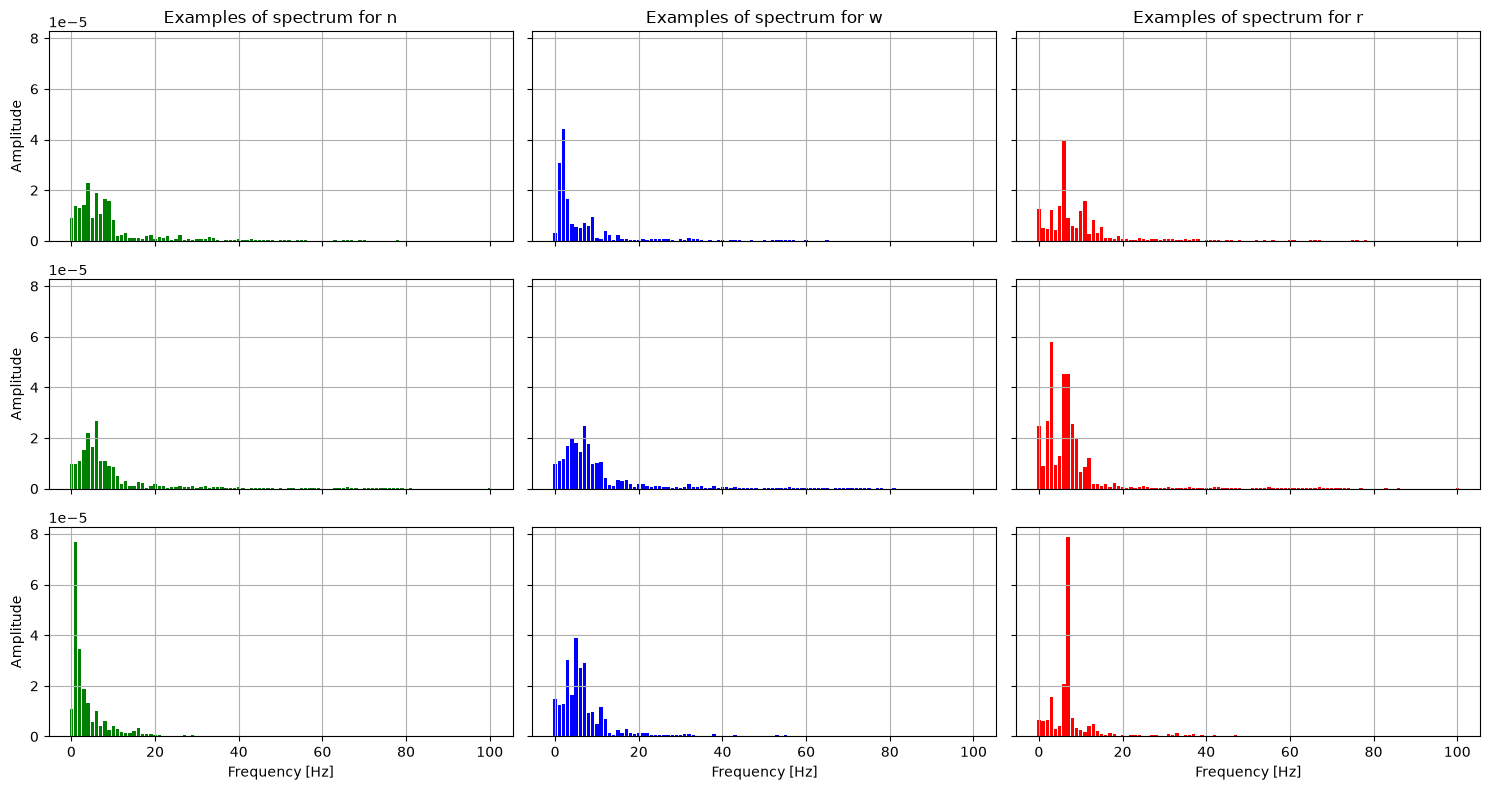

In [4]:
# Get unique states in the "state" column
unique_states = data_mice['state'].unique()

# Set up a color map for each state
color_map = {'w': 'blue', 'n': 'green', 'r': 'red'}

# Create a figure with a 3x3 grid of subplots
fig, axs = plt.subplots(3, 3, figsize=(15, 8), sharey=True, sharex=True)

# Iterate over rows
for i in range(3):
    # Iterate over states
    for j, state in enumerate(unique_states):
        # Filter the data for the current state
        state_data = data_mice[data_mice['state'] == state].iloc[i, 2:]
        
        # Create a bar plot for the current state with the corresponding color
        axs[i, j].bar(np.arange(len(state_data)), state_data, color=color_map[state],width=0.8)
        axs[j, i].grid()
        
        # Set labels for the first row of subplots
        if i == 0:
            axs[i, j].set_title(f"Examples of spectrum for {state}")

# Set common labels
for i in range(3):
    axs[i, 0].set_ylabel("Amplitude")
for j in range(3):
    axs[2, j].set_xlabel("Frequency [Hz]")

plt.tight_layout()
plt.show()

**Q1.1**

Most of the electrical activity occurs at low frequencies. In all three states, the amplitude is highest below 10 Hz, drops quickly between 10 and 20 Hz, and is close to zero above 30 Hz.

The amplitude between 1 and 20 Hz accounts for 84% of the total for 'w' and 91% for 'n'. The peak depends on the state: 'w' is highest at 1 Hz, 'n' has a broad bump from 2 to 9 Hz, and 'r' has a sharp peak at 8 Hz.


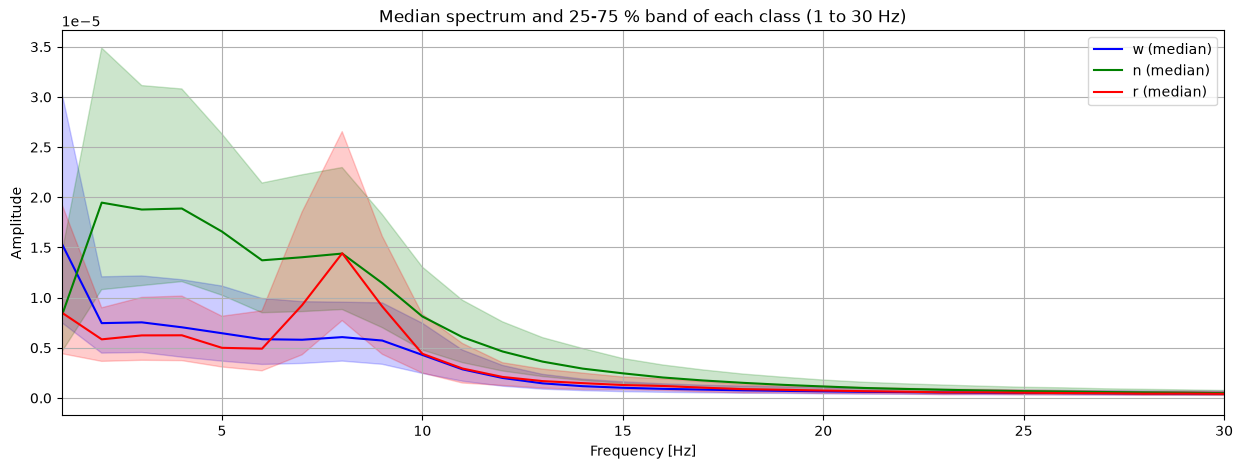

In [ ]:
# report
# Median spectrum (line) and 25-75 % band (shaded area) of each class
spectra = data_mice.drop(['EEGv', 'state'], axis=1)
frequencies = np.arange(1, spectra.shape[1] + 1)

fig, ax = plt.subplots(figsize=(15, 5))
for state in ['w', 'n', 'r']:
    state_spectra = spectra[data_mice['state'] == state]
    ax.plot(frequencies, state_spectra.median(), color=color_map[state], label=f"{state} (median)")
    ax.fill_between(frequencies, state_spectra.quantile(0.25), state_spectra.quantile(0.75), color=color_map[state], alpha=0.2)
ax.set_xlim(1, 30)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude")
ax.set_title("Median spectrum and 25-75 % band of each class (1 to 30 Hz)")
ax.legend()
ax.grid()
plt.show()

**Q1.2**

It is difficult to distinguish them because the intra-class variability is high. The figure above shows the median spectrum of each class (line) and the band that holds the middle 50 % of the rows (25-75 %). Even though the medians are different, the bands overlap at almost all frequencies. The band of 'w' overlaps those of 'n' and 'r' everywhere, and 'n' and 'r' only separate between 2 and 5 Hz. This means the variations within a single class are almost as large as the differences between the classes, making it hard to classify a single sample.


## DECISION TREE

We will now build our first models to predict the state of the mouse. In order to do that, we will create X (=input) and Y (=target), normalize X, and split the dataset into a train and a test set.

In this notebook, we will use single decision tree classifiers. In the next notebook, we will be looking at random forests and other ensembles of decision trees.

In [5]:
#CREATE X AND Y FROM DATAFRAME / NORMALIZE X / SPLIT THE DATA INTO TRAIN/TEST
X = data_mice.drop(['EEGv','state'],axis=1).to_numpy()
X = MinMaxScaler().fit_transform(X)
Y = data_mice['state'].values

# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

#### Model 1

Model 1 is a very basic decision tree implemented with the sklearn library. Main criteria to determine how to split the data at each node include gini impurity and entropy.

Q1.3: Describe both of these criteria. What does a gini impurity of 0 means? What does an entropy of 1 mean?

In [8]:
# Create and train a DecisionTreeClassifier
criterion='entropy'#'entropy'#
DecisionTree_clf = DecisionTreeClassifier(criterion=criterion)
DecisionTree_clf = DecisionTree_clf.fit(X_train, Y_train)

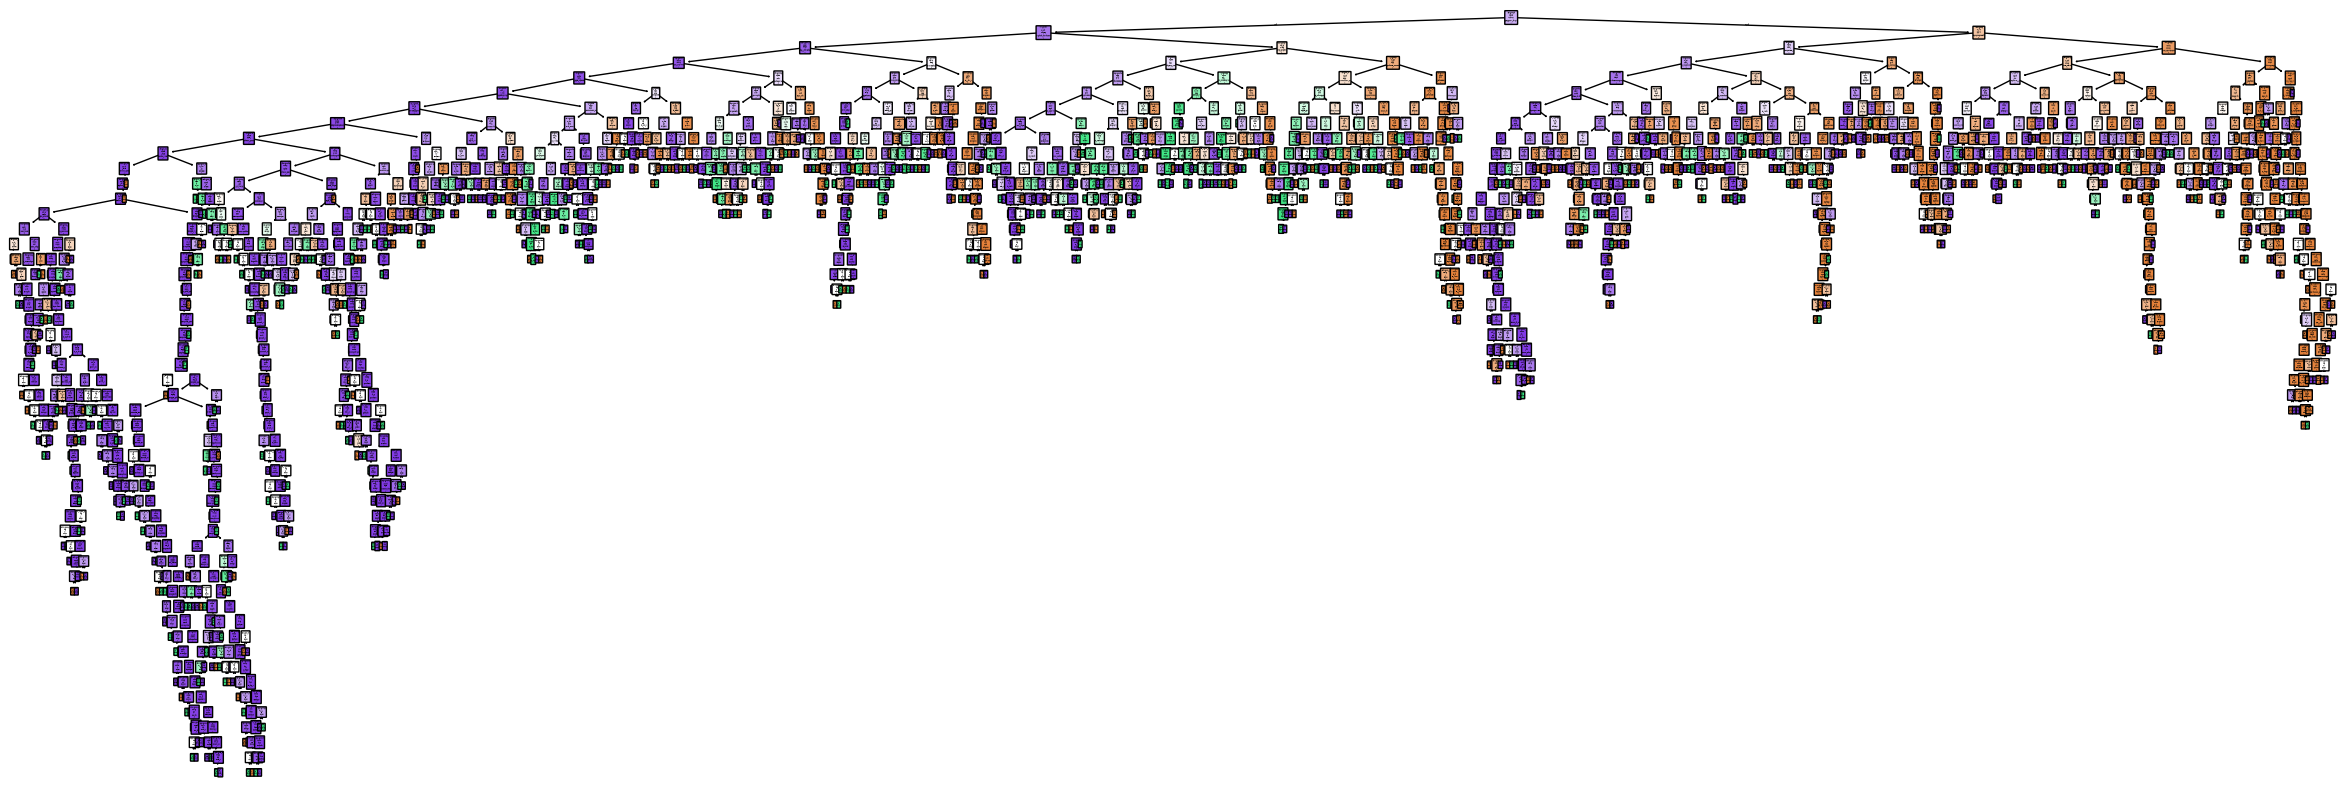

In [7]:
# Visualize model1 (it might take a bit of time as this tree is very big) 
fig, ax = plt.subplots(figsize=(30, 10))#figsize=(50, 25)
tree_plot = plot_tree(DecisionTree_clf, filled=True, feature_names=None, class_names=list(DecisionTree_clf.classes_), rounded=True,label ='none')#, fontsize=12
plt.show()

Accuracy on Training Set: 1.0
Accuracy on Test Set: 0.802319842053307
Classification Report for Training Set:
              precision  recall  f1-score  support
n                   1.0     1.0       1.0   5365.0
r                   1.0     1.0       1.0   1074.0
w                   1.0     1.0       1.0   9767.0
accuracy            1.0     1.0       1.0      1.0
macro avg           1.0     1.0       1.0  16206.0
weighted avg        1.0     1.0       1.0  16206.0
Classification Report for Test Set:
              precision    recall  f1-score     support
n              0.804522  0.801599  0.803058  1376.00000
r              0.311189  0.328413  0.319569   271.00000
w              0.859708  0.856133  0.857917  2405.00000
accuracy       0.802320  0.802320  0.802320     0.80232
macro avg      0.658473  0.662048  0.660181  4052.00000
weighted avg   0.804282  0.802320  0.803282  4052.00000


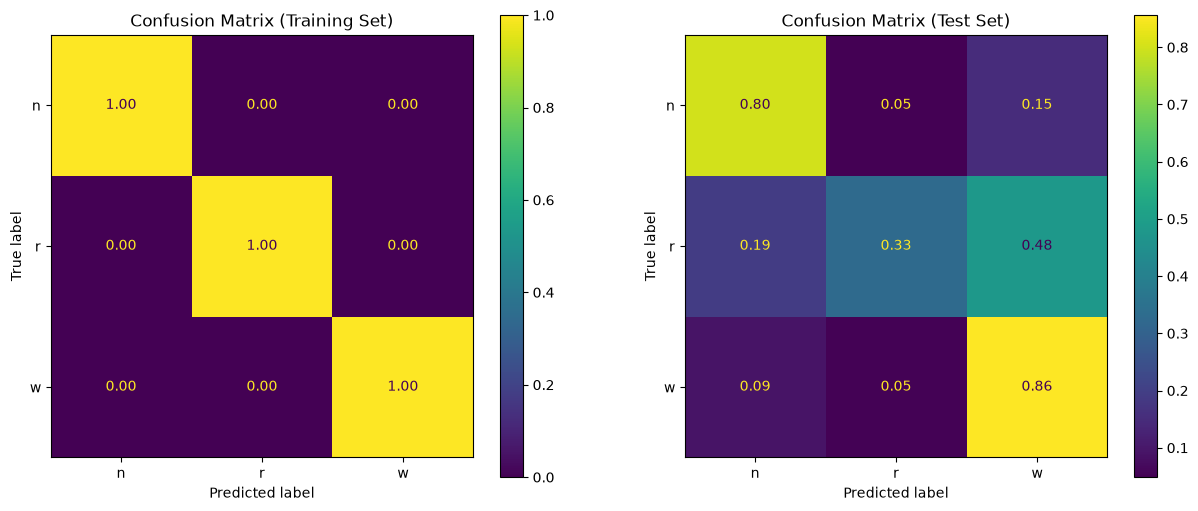

In [8]:
# Make predictions
train_prediction = DecisionTree_clf.predict(X_train)
test_prediction = DecisionTree_clf.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize='true')
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=DecisionTree_clf.classes_)
_=disp_train.plot(ax=axs[0], values_format=".2f")
_=axs[0].set_title('Confusion Matrix (Training Set)')

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize='true')
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=DecisionTree_clf.classes_)
_=disp_test.plot(ax=axs[1], values_format=".2f")
_=axs[1].set_title('Confusion Matrix (Test Set)')

# Display accuracy for both sets
print('Accuracy on Training Set:', train_accuracy)
print('Accuracy on Test Set:', test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(Y_train, train_prediction, output_dict=True)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(Y_test, test_prediction, output_dict=True)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()


**Q1.3**

Both criteria measure the "impurity" (mix) of classes within a node.
- Gini impurity represents the likelihood of misclassifying an element if it were randomly assigned a class based on the node's distribution. A value of 0 indicates a perfectly pure node, where all observations belong to a single class.

- Entropy measures the information uncertainty in bits. For a two-class problem, an entropy of 1 signifies maximum uncertainty, occurring when both classes are equally distributed (50/50).



Q1.4: This problem suffers from a common issue in machine learning. What is this problem called? What could be its causes? How can it be resolved?

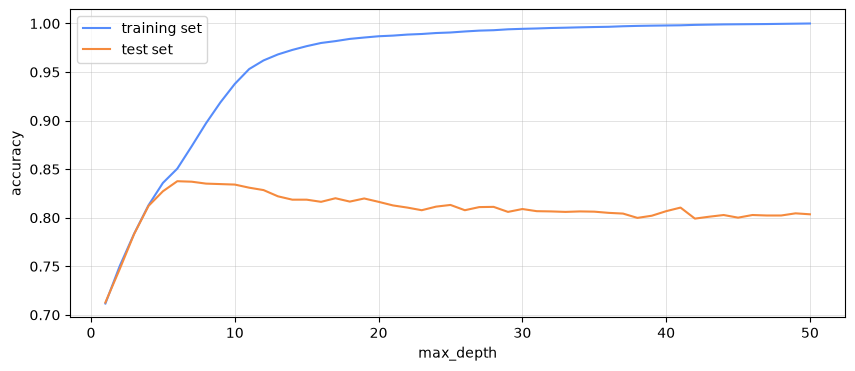

best test accuracy: 0.838 at max_depth = 6


In [9]:
# report
depths = []
train_scores = []
test_scores = []
for d in range(1, 51):
    clf = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=0)
    clf = clf.fit(X_train, Y_train)
    depths.append(d)
    train_scores.append(accuracy_score(Y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(Y_test, clf.predict(X_test)))

plt.figure(figsize=(10, 4))
plt.plot(depths, train_scores, label='training set')
plt.plot(depths, test_scores, label='test set')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.legend()
plt.grid()
plt.show()
print("best test accuracy:", round(max(test_scores), 3), "at max_depth =", depths[np.argmax(test_scores)])

**Q1.4**

Model 1 is overfitting the data. While it achieves perfect accuracy (1.00) on the training set, its performance drops to about 0.80 on the test set. This is because nothing limits the growth of the tree. It grows very deep (about 25 levels and more than 1,000 leaves) and memorizes the noise in the training data instead of learning general patterns.

The graph we made shows that as max_depth increases, the training accuracy reaches 1.0, while the test accuracy reaches a peak at depth 6 and then begins to decline. The widening gap between the two lines is a clear visual sign of overfitting.

By limiting the tree's complexity, we can improve generalization, for example, the best test accuracy is achieved at a max_depth of 6 (0.838).


#### Model 2

Model 2 introduces two additional hyperparameters: min_samples_leaf and max_depth.

In [10]:
# Create and train a DecisionTreeClassifier
criterion='gini'
DecisionTree_clf2 = DecisionTreeClassifier(criterion=criterion,min_samples_leaf=20,max_depth=4)#
DecisionTree_clf2 = DecisionTree_clf2.fit(X_train, Y_train)

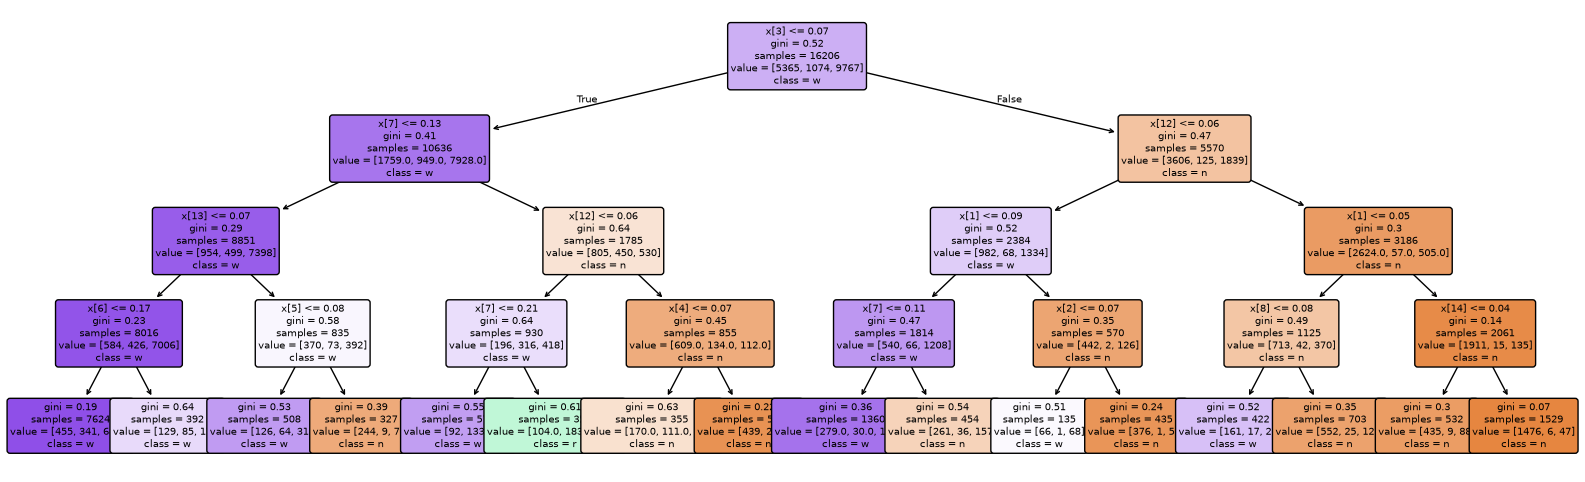

In [11]:
# report
# Visualize model2
fig, ax = plt.subplots(figsize=(20, 6))#figsize=(50, 25)
tree_plot = plot_tree(DecisionTree_clf2, filled=True, feature_names=None, class_names=list(DecisionTree_clf2.classes_), rounded=True, fontsize=7,precision=2)#
plt.show()
fig.savefig("decision_tree_model2.png") 

Q1.5: Use the visualization of this tree to show and explain:

- What is a node? What is an edge? What is a leaf?
- What are the two additional hyperparameters doing? Do you think that both are necessary in this particular case (min_samples_leaf = 20, max_depth= 4)? Why? 
- What does the color of each node represent?

Q1.6: Choose one of the nodes. Explain precisely the information given on each line of text in this node.

Feel free to change min_samples_leaf and max_depth to explore their effects on the tree

Accuracy on Training Set: 0.8129087992101691
Accuracy on Test Set: 0.8121915103652517
Classification Report for Training Set:
              precision    recall  f1-score       support
n              0.817580  0.736813  0.775098   5365.000000
r              0.516949  0.170391  0.256303   1074.000000
w              0.820369  0.925361  0.869707   9767.000000
accuracy       0.812909  0.812909  0.812909      0.812909
macro avg      0.718299  0.610855  0.633703  16206.000000
weighted avg   0.799337  0.812909  0.797736  16206.000000
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.825371  0.728198  0.773745  1376.000000
r              0.567308  0.217712  0.314667   271.000000
w              0.815655  0.927235  0.867873  2405.000000
accuracy       0.812192  0.812192  0.812192     0.812192
macro avg      0.736111  0.624382  0.652095  4052.000000
weighted avg   0.802345  0.812192  0.798910  4052.000000


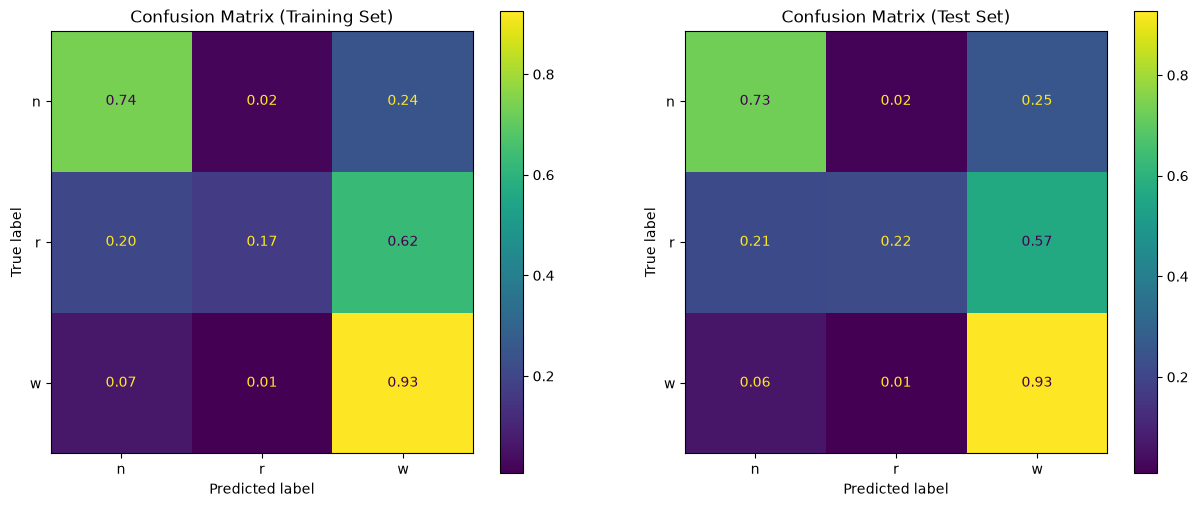

In [11]:
# report
# Make predictions
train_prediction = DecisionTree_clf2.predict(X_train)
test_prediction = DecisionTree_clf2.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize='true')
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=DecisionTree_clf2.classes_)
_=disp_train.plot(ax=axs[0], values_format=".2f")
_=axs[0].set_title('Confusion Matrix (Training Set)')

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize='true')
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=DecisionTree_clf2.classes_)
_=disp_test.plot(ax=axs[1], values_format=".2f")
_=axs[1].set_title('Confusion Matrix (Test Set)')

# Display accuracy for both sets
print('Accuracy on Training Set:', train_accuracy)
print('Accuracy on Test Set:', test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(Y_train, train_prediction, output_dict=True,zero_division=0)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(Y_test, test_prediction, output_dict=True,zero_division=0)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

**Q1.5**

Tree Vocabulary:
 - Node: A box in the tree.
 - Routing Node: A node that performs a test (e.g., x[i] ≤ threshold).
 - Edge: An arrow. Left = True, Right = False.
 - Leaf: A terminal node (bottom) that provides the final class prediction.

 Model 2 Observations:
 - Structure: 15 routing nodes and 16 leaves.
 - Hyperparameters:
     - max_depth=4 was the primary constraint, limiting the tree to 16 leaves.
     - min_samples_leaf=20 was not necessary here, as the smallest leaf already contained 135 rows.
 - Node Colors: Indicate the majority class (Orange = n, Green = r, Purple = w). Color intensity represents how dominant that class is in the node.


**Q1.6**

We choose the root node. Here is its information:

 - Test Condition: x[3] ≤ 0.07 (Amplitude around 4 Hz).
 - Split Direction:
     - ≤ 0.07 → Left (True)
     - \> 0.07 → Right (False)
 - Statistics:
     - Gini Impurity: 0.52
     - Samples: 16,206 (The entire training set)
     - Class Distribution: n = 5365, r = 1074, w = 9767
 - Prediction: Class 'w' (the majority class).


Q1.7: Does model 2 still have the same problem as model 1? Explain based on the classification reports and the confusion matrices.

Q1.8: One of the class seems more difficult to predict than others? Which one? Where could this difficulty come from in your opinion?

**Q1.7**
Model 2 generalizes much better than Model 1. While Model 1 had a huge gap between training (1.00) and test (0.80) accuracy, Model 2 shows almost identical scores on both (~0.81). The confusion matrices and performance reports are also nearly identical for both training and test sets, which confirms that the model has learned robust patterns. However, this reduction in complexity comes at a cost for class 'r', whose recall is significantly lower in Model 2 (0.22 on the test set) compared to Model 1 (0.33).


**Q1.8**
 Class 'r' (REM sleep) is the most difficult to classify. Model 2 reaches a recall of only 0.22 (F1 score 0.31) on the test set, and even Model 1, which has no limits, only reaches 0.33 (F1 score 0.32). Most missed 'r' samples are misclassified as 'w'. This difficulty is driven by two main factors.
 First, there is a significant class imbalance: 'r' represents only 6.6% of the training data, meaning the tree focuses more on the more frequent 'w' and 'n' classes. Second, the 25-75 % bands of 'r' and 'w' overlap at all 101 frequencies (see Q1.2). The clearest difference is the peak of 'r' around 8 Hz, but even there the two bands still overlap a little. This is why many 'r' rows look like 'w' rows.


#### Model 3

Model 3 is supposed to solve the difficulty encountered by model 2 thanks to class_weight='balanced'. 

Q1.9: What does this hyperparameter do ? Explain giving examples from this dataset.

In [12]:
# Create and train a DecisionTreeClassifier
criterion='gini'
DecisionTree_clf3 = DecisionTreeClassifier(criterion=criterion,min_samples_leaf=20,max_depth=4,class_weight='balanced')
DecisionTree_clf3 = DecisionTree_clf3.fit(X_train, Y_train)

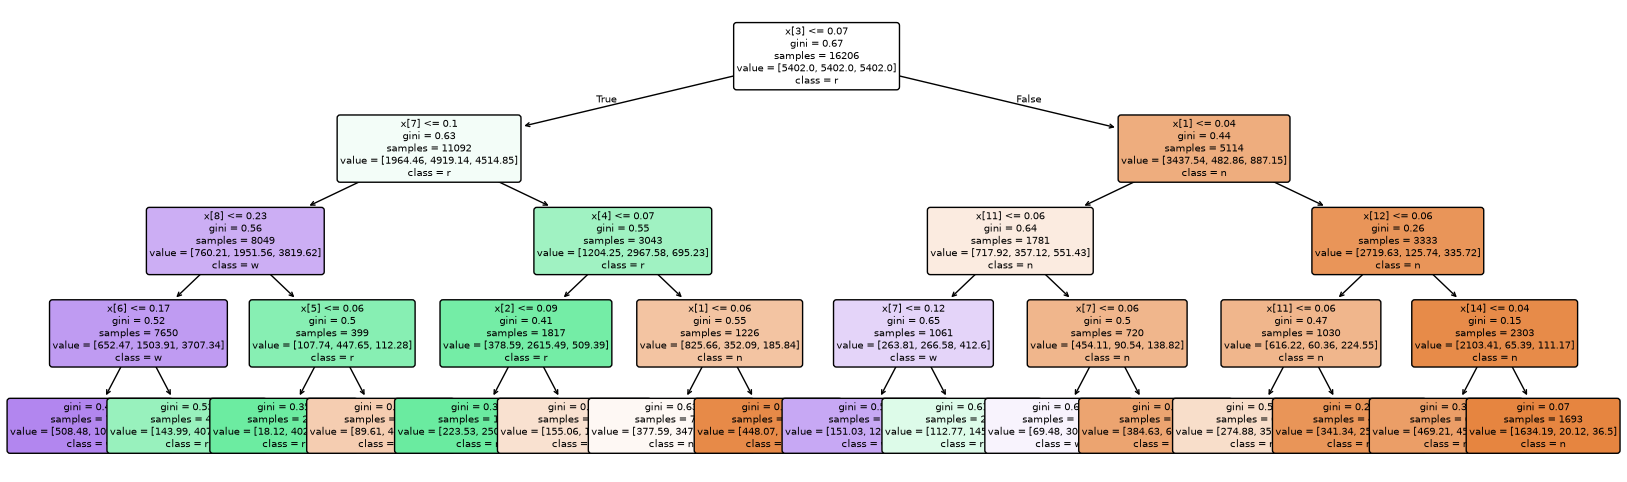

In [13]:
# Visualize model3
fig, ax = plt.subplots(figsize=(20, 6))
tree_plot = plot_tree(DecisionTree_clf3, filled=True, feature_names=None, class_names=list(DecisionTree_clf3.classes_), rounded=True, fontsize=7,precision=2)#
plt.show()

Accuracy on Training Set: 0.7504010860175244
Accuracy on Test Set: 0.7495064165844028
Classification Report for Training Set:
              precision    recall  f1-score       support
n              0.756984  0.772787  0.764804   5365.000000
r              0.283422  0.641527  0.393153   1074.000000
w              0.882863  0.750077  0.811071   9767.000000
accuracy       0.750401  0.750401  0.750401      0.750401
macro avg      0.641090  0.721463  0.656342  16206.000000
weighted avg   0.801465  0.750401  0.768058  16206.000000
Classification Report for Test Set:
              precision    recall  f1-score      support
n              0.768459  0.779070  0.773728  1376.000000
r              0.266200  0.560886  0.361045   271.000000
w              0.869128  0.753846  0.807393  2405.000000
accuracy       0.749506  0.749506  0.749506     0.749506
macro avg      0.634595  0.697934  0.647389  4052.000000
weighted avg   0.794618  0.749506  0.766109  4052.000000


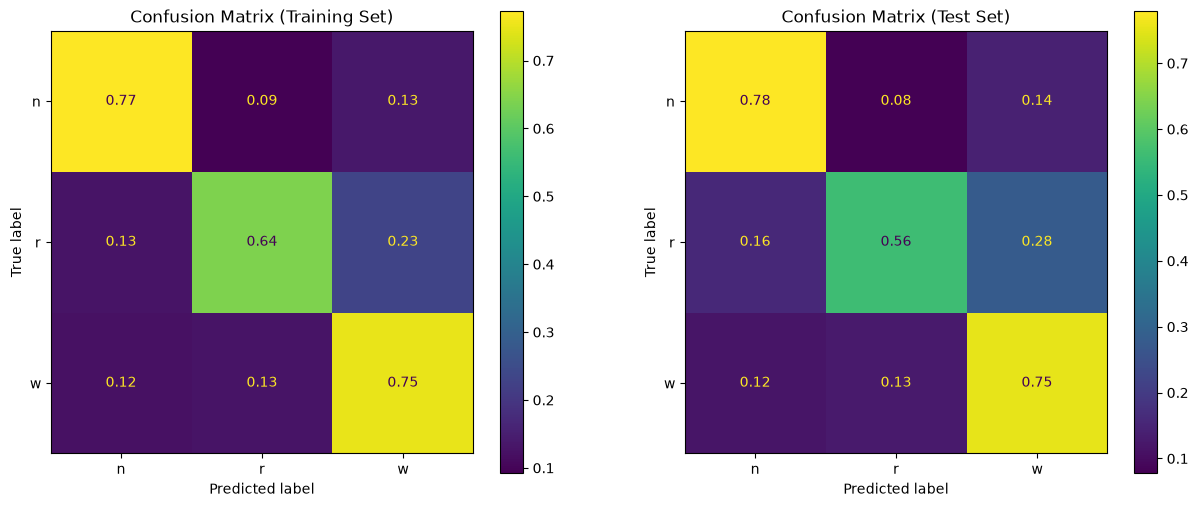

In [14]:
# report
# Make predictions
train_prediction = DecisionTree_clf3.predict(X_train)
test_prediction = DecisionTree_clf3.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(Y_train, train_prediction)
test_accuracy = accuracy_score(Y_test, test_prediction)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Confusion matrix for the training set
cm_train = confusion_matrix(Y_train, train_prediction, normalize='true')
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=DecisionTree_clf3.classes_)
_=disp_train.plot(ax=axs[0], values_format=".2f")
_=axs[0].set_title('Confusion Matrix (Training Set)')

# Confusion matrix for the test set
cm_test = confusion_matrix(Y_test, test_prediction, normalize='true')
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=DecisionTree_clf3.classes_)
_=disp_test.plot(ax=axs[1], values_format=".2f")
_=axs[1].set_title('Confusion Matrix (Test Set)')

# Display accuracy for both sets
print('Accuracy on Training Set:', train_accuracy)
print('Accuracy on Test Set:', test_accuracy)

# Classification report for the training set
classification_metrics_train = classification_report(Y_train, train_prediction, output_dict=True,zero_division=0)
report_df_train = pd.DataFrame(classification_metrics_train).transpose()
print("Classification Report for Training Set:")
print(report_df_train)

# Classification report for the test set
classification_metrics_test = classification_report(Y_test, test_prediction, output_dict=True,zero_division=0)
report_df_test = pd.DataFrame(classification_metrics_test).transpose()
print("Classification Report for Test Set:")
print(report_df_test)

plt.show()

**Q1.9**

Using `class_weight='balanced'` assigns a weight to each class inversely proportional to its frequency. This significantly boosts the importance of the minority class. For example, an 'r' sample receives a weight of approximately 5.03, whereas a 'w' sample only receives 0.55. The tree uses these weights to calculate Gini impurity and to determine leaf predictions. This is clearly visible in Model 3, where a leaf that would normally predict 'w' based on raw counts now predicts 'r' because its weighted count is higher. As a result, Model 3 is much more sensitive to the minority class, identifying 4 leaves for 'r' compared to only 1 in Model 2.


Q1.10: Compare results from model 2 and model 3. What are the pros and cons of each of them? 

**Q1.10**

Model 2 achieves higher overall accuracy (0.812 compared to 0.750 for Model 3) and is very reliable for the 'w' class with a recall of 0.93. However, it misses most REM sleep, showing a low recall of only 0.22. In contrast, Model 3 is much more effective at detecting 'r', with a recall of 0.56 and a better F1 score. This improvement comes at the cost of more false alarms, as Model 3 misclassifies many 'w' rows as 'r', which lowers the precision for the 'r' class. Ultimately, Model 2 is the better choice if overall accuracy is the priority, while Model 3 is better if detecting REM sleep is the main goal and false alarms are acceptable.


NOTE: Those models could be fine-tuned in order to enhance their ability to classify the state of a mouse. You can experiment with hyperparameters if you're interested in improving performance. However, we'll dive deeper into fine-tuning in the next notebook, where we'll explore Random Forests, a more powerful machine learning method. Random Forest is a popular technique that leverages the concept of ensemble learning. The fundamental idea behind it is to train multiple decision trees (like the ones in this notebook), each slightly different from the others, and then combine their outputs through a voting mechanism to make predictions. This ensemble approach typically leads to more robust and accurate predictions.